In [40]:
import pandas as pd           
import numpy as np            
import matplotlib.pyplot as plt  
import seaborn as sns  

In [41]:
ca = pd.read_csv('cust_activity.csv')
cb = pd.read_csv('cust_bio.csv')
cs = pd.read_csv('cust_sub.csv')
orders = pd.read_csv('orders.csv')
sp = pd.read_csv('sp.csv')

In [42]:
print(ca.shape)

(7500, 3)


In [43]:
cb.shape

(478, 3)

In [44]:
cs.shape

(51, 3)

In [45]:
orders.shape

(127, 4)

In [46]:
sp.shape

(6, 5)

In [47]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')


#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df.
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart.
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City.

</pre>


### 1) Check null values and duplicates in each df.


In [48]:
for i in [ca,cb,cs,orders,sp]:
    print(i.isnull().sum())

Cust_ID     0
Activity    0
Date        0
dtype: int64
Cust_ID    0
City       0
Age        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64


In [49]:
# Duplicates
for i in [ca,cb,cs,orders,sp]:
    print(i.duplicated().sum())

0
0
0
0
0


In [50]:
def check_dup(data):
    dup = data.duplicated().sum()
    if dup > 0:
        print(dup)
    else:
        print('No Duplicates')

In [51]:
for i in [ca,cb,cs,orders,sp]:
    check_dup(i)

No Duplicates
No Duplicates
No Duplicates
No Duplicates
No Duplicates


In [52]:
import plotly.express as px

### 2) Find Count of Customers from each city and represent it on bar chart.

In [53]:
q2 = cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


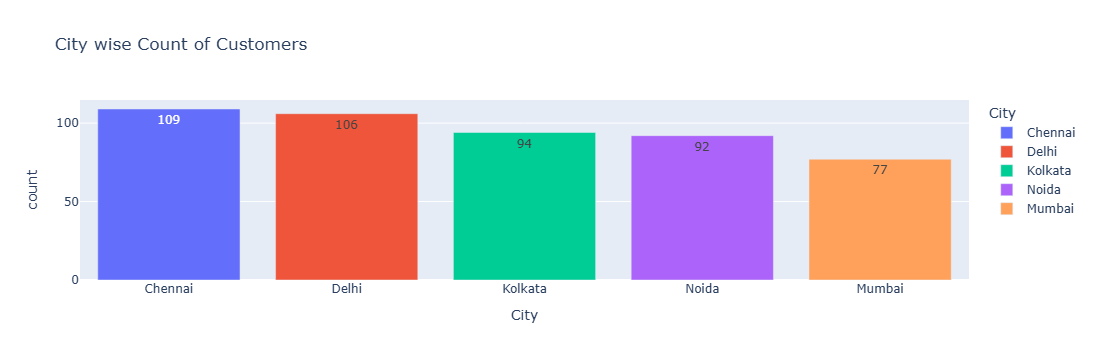

In [54]:
fig = px.bar(data_frame = q2, x ='City',y = 'count',title = 'City wise Count of Customers',
            text = 'count',color = 'City')
fig.show()

### 3) Find Range Age wise count of cutsomers, represent it on pie chart.

In [55]:
cb['Age'].describe()

count    478.000000
mean      28.740586
std        5.376756
min       20.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       37.000000
Name: Age, dtype: float64

In [56]:
cb['Age_Range'] = pd.cut(cb['Age'],bins = [19,24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [57]:
q3 = cb['Age_Range'].value_counts().reset_index()
q3.head()

,Age_Range,count
0,"(19, 24]",137
1,"(29, 34]",130
2,"(24, 29]",120
3,"(34, 39]",91


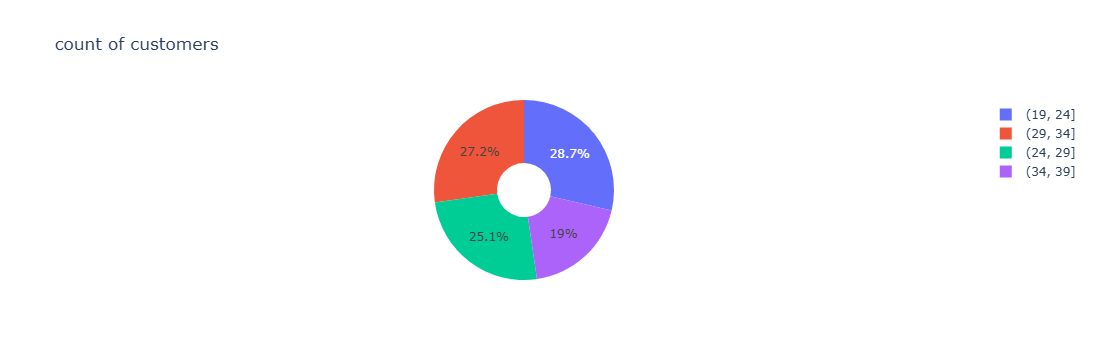

In [58]:
fig = px.pie(data_frame= q3,names = 'Age_Range',values='count',title = 'count of customers',hole=0.3)
fig.show()

### 4) Find Count of each activity, represent it on bar chart

In [59]:
q4 = ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


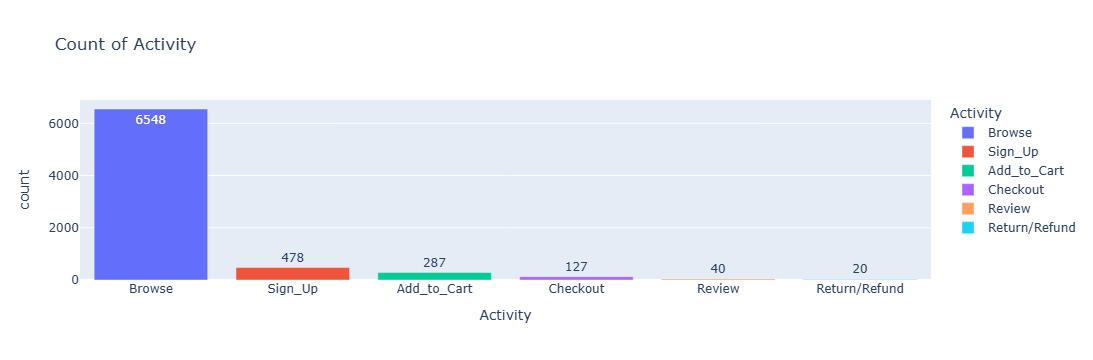

In [60]:
fig = px.bar(data_frame=q4,x ='Activity',y = 'count',title = 'Count of Activity',text= 'count',color='Activity')
fig.show()

### 5) Find order month wise total amount. Represent it on line chart.

In [61]:
ca['Date'] = pd.to_datetime(ca['Date'])
ca['Month'] = ca['Date'].dt.month

In [62]:
ca.columns

Index(['Cust_ID', 'Activity', 'Date', 'Month'], dtype='str')

In [63]:
ca_checkout = ca[ca['Activity'] == 'Checkout']
print(ca_checkout.shape)
print(orders.shape)

(127, 4)
(127, 4)


In [64]:
ca_orders = pd.merge(orders,ca_checkout, on ='Cust_ID',how='inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [65]:
q5 = ca_orders.groupby(ca_orders['Month'])['Amount'].sum().reset_index()
q5.head()

,Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46


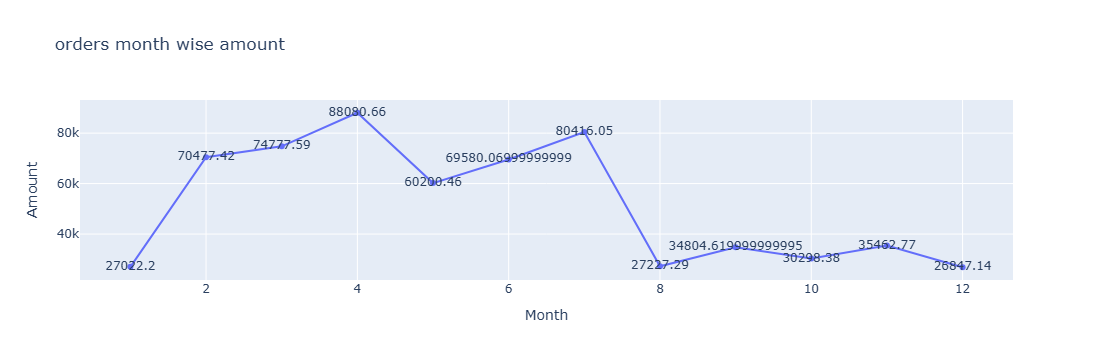

In [66]:
fig = px.line(data_frame = q5,x='Month',y='Amount',title= 'orders month wise amount',text='Amount')
fig.show()

### 6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.

In [67]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.columns)

Index(['Cust_ID', 'Activity', 'Date', 'Month'], dtype='str')
Index(['Cust_ID', 'City', 'Age', 'Age_Range'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')


In [68]:
sp.head()

,Plan_Var_ID,Plan_ID,Plan_name,Price,Duration
0,P1_1Y,P1,Silver,1200.0,1 Year
1,P1_6M,P1,Silver,720.0,6 Months
2,P2_1Y,P2,Gold,2400.0,1 Year
3,P2_6M,P2,Gold,1440.0,6 Months
4,P3_1Y,P3,Diamond,4800.0,1 Year


In [69]:
cs.head()

,Cust_ID,Plan_Var_ID,Purchase_Date
0,CUS_626,P1_1Y,2025-05-15
1,CUS_723,P1_1Y,2024-07-23
2,CUS_575,P1_1Y,2024-11-14
3,CUS_232,P2_6M,2025-04-19
4,CUS_346,P2_1Y,2024-01-31


In [70]:
cs_sp= pd.merge(cs,sp, on ='Plan_Var_ID',how='inner')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [71]:
q6 = cs_sp.groupby(['Plan_Var_ID'])['Price'].sum().reset_index()
q6.head()

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0


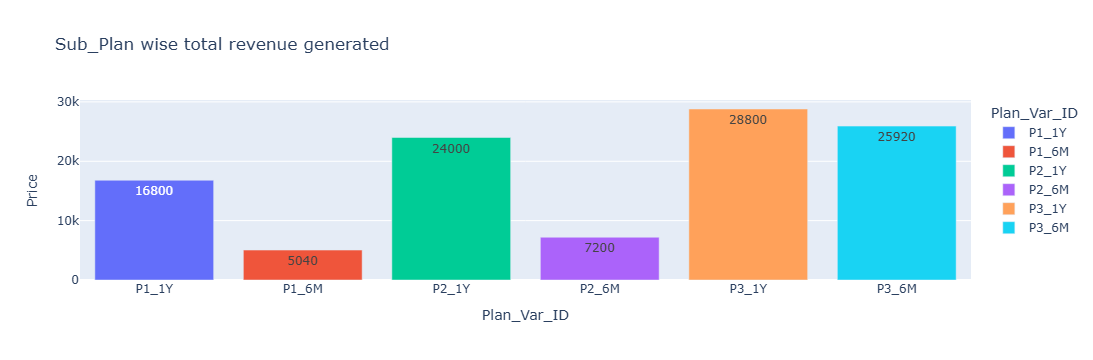

In [72]:
fig = px.bar(data_frame = q6,x='Plan_Var_ID',y='Price',title= 'Sub_Plan wise total revenue generated',text='Price',color='Plan_Var_ID')
fig.show()

### 7) City wise find total amount

In [73]:
orders.head()

,Order_id,Cust_ID,Amount,Payment_mode
0,ORD_71,CUS_545,2123.19,UPI
1,ORD_72,CUS_622,2788.02,Net Banking
2,ORD_73,CUS_418,3071.63,Credit_Card
3,ORD_74,CUS_360,5736.31,COD
4,ORD_75,CUS_714,1592.53,Debit Card


In [74]:
cb.head()

,Cust_ID,City,Age,Age_Range
0,CUS_121,Noida,30,"(29, 34]"
1,CUS_124,Kolkata,20,"(19, 24]"
2,CUS_125,Kolkata,24,"(19, 24]"
3,CUS_126,Chennai,24,"(19, 24]"
4,CUS_127,Delhi,24,"(19, 24]"


In [75]:
c_amount = pd.merge(orders,cb ,on ='Cust_ID',how='inner')
c_amount

,Order_id,Cust_ID,Amount,Payment_mode,City,Age,Age_Range
0,ORD_71,CUS_545,2123.19,UPI,Delhi,25,"(24, 29]"
1,ORD_72,CUS_622,2788.02,Net Banking,Kolkata,27,"(24, 29]"
2,ORD_73,CUS_418,3071.63,Credit_Card,Noida,23,"(19, 24]"
3,ORD_74,CUS_360,5736.31,COD,Noida,25,"(24, 29]"
4,ORD_75,CUS_714,1592.53,Debit Card,Mumbai,29,"(24, 29]"
...,...,...,...,...,...,...,...
122,ORD_193,CUS_512,5509.80,Credit_Card,Kolkata,31,"(29, 34]"
123,ORD_194,CUS_292,6409.17,Credit_Card,Noida,36,"(34, 39]"
124,ORD_195,CUS_372,6715.57,Credit_Card,Delhi,27,"(24, 29]"
125,ORD_196,CUS_795,4226.04,COD,Chennai,32,"(29, 34]"


q7 = c_amount.groupby(c_amount['City'])['Amount'].sum().reset_index()
q7.head()

### 8) Find count of each payment mode, represent it on donut chart

In [76]:
orders.head()

,Order_id,Cust_ID,Amount,Payment_mode
0,ORD_71,CUS_545,2123.19,UPI
1,ORD_72,CUS_622,2788.02,Net Banking
2,ORD_73,CUS_418,3071.63,Credit_Card
3,ORD_74,CUS_360,5736.31,COD
4,ORD_75,CUS_714,1592.53,Debit Card


In [77]:
q7= orders['Payment_mode'].value_counts().reset_index()
q7.head()

,Payment_mode,count
0,Net Banking,29
1,Debit Card,27
2,UPI,24
3,Credit_Card,24
4,COD,23


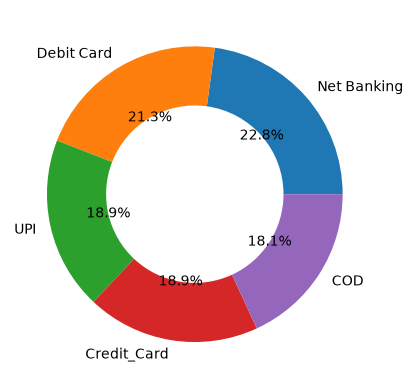

In [94]:
plt.pie(q7['count'],labels=q7['Payment_mode'],autopct='%1.1f%%',wedgeprops={'width': 0.4})
plt.show()

### 9) Represent Payment mode wise sum of amount on a strip plot

In [95]:
payment_amount = orders.groupby(['Payment_mode'])['Amount'].sum().reset_index()
payment_amount

,Payment_mode,Amount
0,COD,115972.27
1,Credit_Card,127611.89
2,Debit Card,133145.11
3,Net Banking,137780.34
4,UPI,110685.04


In [96]:
orders.head()

,Order_id,Cust_ID,Amount,Payment_mode
0,ORD_71,CUS_545,2123.19,UPI
1,ORD_72,CUS_622,2788.02,Net Banking
2,ORD_73,CUS_418,3071.63,Credit_Card
3,ORD_74,CUS_360,5736.31,COD
4,ORD_75,CUS_714,1592.53,Debit Card


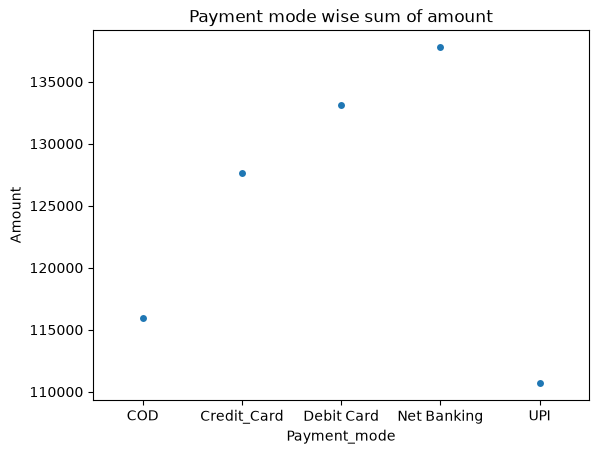

In [97]:
sns.stripplot(x='Payment_mode',y ='Amount',data=payment_amount)
plt.title('Payment mode wise sum of amount')
plt.show()

### 1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

In [98]:
w1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='count')
w1.head()

,Cust_ID,Activity,count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [99]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [100]:
funnel['Prev_count'] = np.where(funnel['Activity']=='Return/Refund',
                                funnel['count'].shift(2),
                                funnel['count'].shift(1))
funnel

,Activity,count,Prev_count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [101]:
funnel['Prev_conversion'] = round((funnel['count']/funnel['Prev_count'])*100,2)
funnel.fillna(0,inplace=True)
funnel

,Activity,count,Prev_count,Prev_conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [102]:
funnel['Prev_conversion'] = funnel['Prev_conversion'].apply(lambda x : str(x) + '%')
funnel

,Activity,count,Prev_count,Prev_conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


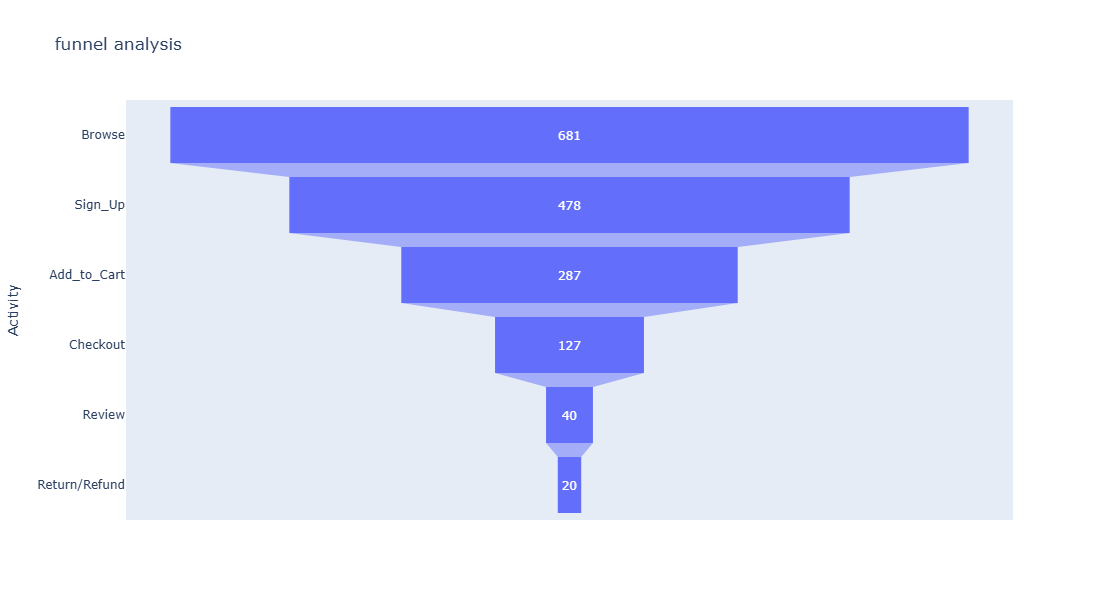

In [103]:
fig = px.funnel(data_frame=funnel,y ='Activity',x='count',
                title='funnel analysis', height=600,hover_data='Prev_conversion')
fig.show()

### 2) Find Customer wise count of days to transition from one stage of funnel to the next stage

In [104]:
pt1= pd.pivot_table(data=ca,index=['Cust_ID'],columns=['Activity'],
                    values='Date',aggfunc='min')
pt1.head(10)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [105]:
# DD = DateDiff
pt1['DD_Browse_2_Signup'] = (pt1['Browse'] - pt1['Sign_Up']).dt.days
pt1['DD_Signup_2_Add2cart'] = (pt1['Add_to_Cart'] -  pt1['Sign_Up']).dt.days
pt1['DD_Add2cart_2_Checkout'] = (pt1['Checkout'] -  pt1['Add_to_Cart']).dt.days
pt1['DD_Checkout_2_Review'] = (pt1['Review'] -  pt1['Checkout']).dt.days
pt1['DD_Checkout_2_Return/Refund'] = (pt1['Return/Refund'] -  pt1['Checkout']).dt.days
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2cart,DD_Add2cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN


In [106]:
pt2 = pt1.iloc[:,-5:]
pt2.head(2)

Activity,DD_Browse_2_Signup,DD_Signup_2_Add2cart,DD_Add2cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,
CUS_121,3.0,3.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN


In [108]:
tran_days = pt2.mean()
tran_days

Activity
DD_Browse_2_Signup              1.550209
DD_Signup_2_Add2cart            2.512195
DD_Add2cart_2_Checkout         14.425197
DD_Checkout_2_Review            2.625000
DD_Checkout_2_Return/Refund     3.400000
dtype: float64

In [109]:
avg_days_to_tran = [0] + list(tran_days.values)
print(avg_days_to_tran)

[0, np.float64(1.5502092050209204), np.float64(2.5121951219512195), np.float64(14.4251968503937), np.float64(2.625), np.float64(3.4)]


In [110]:
funnel['Avg_days_2tran'] = avg_days_to_tran
funnel['Avg_days_2tran'] = funnel['Avg_days_2tran'].apply(lambda x : round(x,2))
funnel

,Activity,count,Prev_count,Prev_conversion,Avg_days_2tran
0,Browse,681,0.0,0.0%,0.00
1,Sign_Up,478,681.0,70.19%,1.55
2,Add_to_Cart,287,478.0,60.04%,2.51
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


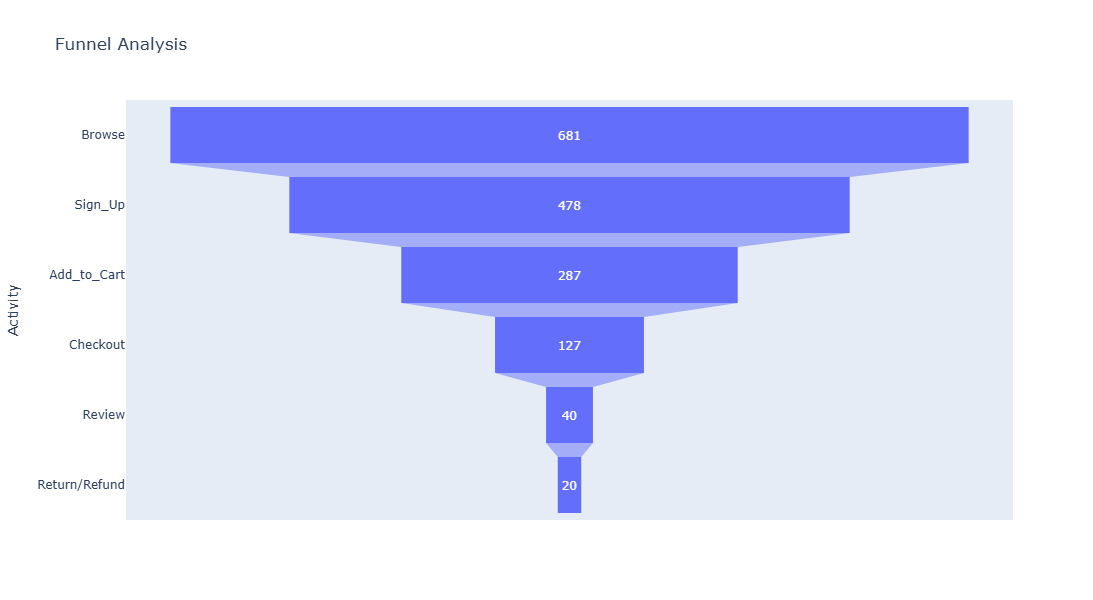

In [123]:
fig1 = px.funnel(data_frame=funnel, y = 'Activity', x = 'count',title='Funnel Analysis',height = 600,hover_data ='Avg_days_2tran')
fig1.show()

### 3) Find Avg_Days to transition from one Funnel stage to the next stage.

### 4) Create function to analyse Funnel based on City.

In [ ]:
def city_wise_funnel(city_name):
    city_df = cb[cv['city']==city_name]

#### Window Function in pandas

1) lead, leg - shift
2) rank, dense_rank, row_number - rank

In [127]:
demo = pd.DataFrame({'City':['Delhi']*5 + ['Noida']*5 + ['Pune']*5,
                     'Sales': [5000,6000,6000,7500,9000,3500,4200,5400,8700,8700,
                               11500,14500,18000,18000,18000],
                     'Year' : [2015,2016,2017,2018,2019]*3})
demo

,City,Sales,Year
0,Delhi,5000,2015
1,Delhi,6000,2016
2,Delhi,6000,2017
3,Delhi,7500,2018
4,Delhi,9000,2019
5,Noida,3500,2015
6,Noida,4200,2016
7,Noida,5400,2017
8,Noida,8700,2018
9,Noida,8700,2019


In [128]:
demo1 = demo.copy()

In [129]:
noida = demo.query("City=='Noida'")
noida

,City,Sales,Year
5,Noida,3500,2015
6,Noida,4200,2016
7,Noida,5400,2017
8,Noida,8700,2018
9,Noida,8700,2019


In [132]:
noida['Rank_min'] = noida['Sales'].rank(ascending=False,method='min')
noida['Rank_max'] = noida['Sales'].rank(ascending=False,method='max')
noida['Rank_avg'] = noida['Sales'].rank(ascending=False,method='average')
noida['Rank_first'] = noida['Sales'].rank(ascending=False,method='first')   # row number
noida['Rank_dense'] = noida['Sales'].rank(ascending=False,method='dense')
noida

,City,Sales,Year,Rank_min,Rank_max,Rank_avg,Rank_first,Rank_dense
5,Noida,3500,2015,5.0,5.0,5.0,5.0,4.0
6,Noida,4200,2016,4.0,4.0,4.0,4.0,3.0
7,Noida,5400,2017,3.0,3.0,3.0,3.0,2.0
8,Noida,8700,2018,1.0,2.0,1.5,1.0,1.0
9,Noida,8700,2019,1.0,2.0,1.5,2.0,1.0


In [ ]:
### Find City wise Top 3 sales ? - use demo1
# select * from
# (select city,sales, row_number() over (partition by city order by sales desc) RN from demo1) dt where RN <=3;

In [133]:
demo2 = demo1.copy()

In [134]:
demo1['Rank'] = demo1.groupby('City')['Sales'].rank(ascending = False , method = 'dense')
demo1

,City,Sales,Year,Rank
0,Delhi,5000,2015,4.0
1,Delhi,6000,2016,3.0
2,Delhi,6000,2017,3.0
3,Delhi,7500,2018,2.0
4,Delhi,9000,2019,1.0
5,Noida,3500,2015,4.0
6,Noida,4200,2016,3.0
7,Noida,5400,2017,2.0
8,Noida,8700,2018,1.0
9,Noida,8700,2019,1.0


In [135]:
top3 = demo1[demo1['Rank']<=3]
top3

,City,Sales,Year,Rank
1,Delhi,6000,2016,3.0
2,Delhi,6000,2017,3.0
3,Delhi,7500,2018,2.0
4,Delhi,9000,2019,1.0
6,Noida,4200,2016,3.0
7,Noida,5400,2017,2.0
8,Noida,8700,2018,1.0
9,Noida,8700,2019,1.0
10,Pune,11500,2015,3.0
11,Pune,14500,2016,2.0


### Q) Find city and sales where sales is more than avg sales for that city?

In [136]:
demo2.head()

,City,Sales,Year
0,Delhi,5000,2015
1,Delhi,6000,2016
2,Delhi,6000,2017
3,Delhi,7500,2018
4,Delhi,9000,2019


In [ ]:
## select d2.city,d2.sales from demo2 d2 where d2.sales > (select avg(sales) from demo2 d1 where d1.city = d2.city);

In [141]:
w1 = demo2.groupby('City')['Sales'].mean().reset_index()
w1.columns = ['City','Avg_Sales']
w1

,City,Avg_Sales
0,Delhi,6700.0
1,Noida,6100.0
2,Pune,16000.0


In [143]:
w2 = pd.merge(demo2,w1,on='City')
res = w2[w2['Sales']>w2['Avg_Sales']]
res

,City,Sales,Year,Avg_Sales
3,Delhi,7500,2018,6700.0
4,Delhi,9000,2019,6700.0
8,Noida,8700,2018,6100.0
9,Noida,8700,2019,6100.0
12,Pune,18000,2017,16000.0
13,Pune,18000,2018,16000.0
14,Pune,18000,2019,16000.0
